## Interval Analysis

In [ ]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = False
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 200)
        self.fc2 = nn.Linear(200,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = self.fc2(x)
        # x = F.softmax(x, dim=-1) # added softmax for probabilities
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()


100%|██████████| 9.91M/9.91M [00:00<00:00, 59.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.65MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.1MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.78MB/s]


Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=200, bias=True)
    (fc2): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [ ]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        print(f'Accuracy on images: {100 * correct / total}')

In [ ]:
train_model(model, 15)
test_model(model)

Epoch 1/15, Loss: 0.593
Epoch 2/15, Loss: 0.297
Epoch 3/15, Loss: 0.248
Epoch 4/15, Loss: 0.215
Epoch 5/15, Loss: 0.190
Epoch 6/15, Loss: 0.170
Epoch 7/15, Loss: 0.155
Epoch 8/15, Loss: 0.142
Epoch 9/15, Loss: 0.130
Epoch 10/15, Loss: 0.121
Epoch 11/15, Loss: 0.113
Epoch 12/15, Loss: 0.106
Epoch 13/15, Loss: 0.099
Epoch 14/15, Loss: 0.093
Epoch 15/15, Loss: 0.088
Accuracy on images: 97.06


### Write the interval analysis for the simple model

In [ ]:
## TODO: Write the interval analysis for the simple model
## you can use https://github.com/Zinoex/bound_propagation

def input_box(x, eps):
    low  = (x - eps).clamp(0, 1)
    high = (x + eps).clamp(0, 1)
    return low, high

def interval_normalize(low, high):
    new_low  = (low  - 0.1307) / 0.3081
    new_high = (high - 0.1307) / 0.3081
    return new_low, new_high

def interval_linear(low, high, W, b):
    W_pos = W.clamp(min=0)
    W_neg = W.clamp(max=0)
    new_low  = low  @ W_pos.T + high @ W_neg.T + b
    new_high = high @ W_pos.T + low  @ W_neg.T + b
    return new_low, new_high

def interval_relu(low, high):
    new_low  = torch.relu(low)
    new_high = torch.relu(high)
    return new_low, new_high


In [ ]:
def verify(x, y, eps):
    net = model[1]
    low, high = input_box(x, eps)
    low, high = interval_normalize(low, high)
    low, high = low.view(-1, 784), high.view(-1, 784)
    low, high = interval_linear(low, high, net.fc.weight, net.fc.bias)
    low, high = interval_relu(low, high)

    W2 = net.fc2.weight
    b2 = net.fc2.bias
    verified = torch.ones(len(y), dtype=torch.bool)
    for j in range(10):
        W = W2[y] - W2[j]
        b = b2[y] - b2[j]
        margin_low = (W.clamp(min=0) * low).sum(dim=1) + (W.clamp(max=0) * high).sum(dim=1) + b
        verified = verified & (margin_low >= 0)

    return verified


In [ ]:
eps_values = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.10]
accs = []

with torch.no_grad():
    for eps in eps_values:
        verified = 0
        for x, y in test_loader:
            verified += verify(x, y, eps).sum().item()
        acc = 100 * verified / len(test_dataset)
        accs.append(acc)
        print(f"eps = {eps:.2f}   verified accuracy = {acc:.2f}%")

eps = 0.01   verified accuracy = 63.43%
eps = 0.02   verified accuracy = 8.47%
eps = 0.03   verified accuracy = 0.74%
eps = 0.04   verified accuracy = 0.04%
eps = 0.05   verified accuracy = 0.00%
eps = 0.06   verified accuracy = 0.00%
eps = 0.07   verified accuracy = 0.00%
eps = 0.08   verified accuracy = 0.00%
eps = 0.09   verified accuracy = 0.00%
eps = 0.10   verified accuracy = 0.00%


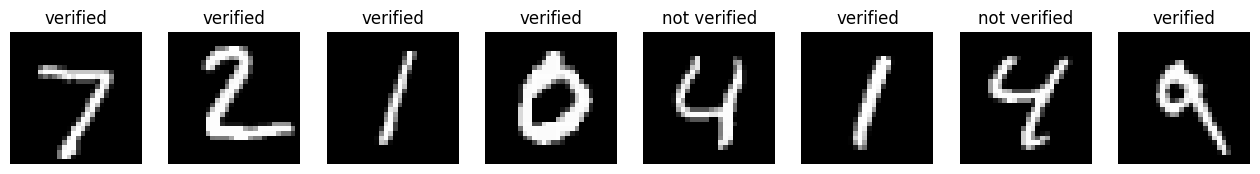

In [ ]:
x, y = next(iter(test_loader))
with torch.no_grad():
    ok = verify(x, y, 0.01)

plt.figure(figsize=(16, 3)) # first 8 test images, verified or not at eps = 0.01
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(x[i, 0], cmap="gray")
    if ok[i]:
        plt.title("verified")
    else:
        plt.title("not verified")
    plt.axis("off")
plt.show()